# Task F — Is the growing airline swing seasonal or scale?

This bonus revisits the Week 1 airline question using the historical
**AirPassengers** monthly series (144 months, 1949–1960), from the R
`datasets` collection mirrored by Vincent Arel-Bundock's Rdatasets project.
The source CSV is included in `assignments/data/air_passengers.csv`, so the
notebook runs offline.

**Citation:** Box, G. E. P. & Jenkins, G. M. (1970), *Time Series Analysis:
Forecasting and Control*; R `datasets::AirPassengers`,
<https://vincentarelbundock.github.io/Rdatasets/doc/datasets/AirPassengers.html>.
CSV source:
<https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/AirPassengers.csv>.
Downloaded 2026-10-22. Monthly category is calendar month (Jan–Dec).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd()
WEEK4_DIR = HERE if (HERE / "assignments" / "data").exists() else HERE / "week4"
ASSIGNMENTS_DIR = WEEK4_DIR / "assignments"
DATA_DIR = ASSIGNMENTS_DIR / "data"
sys.path.insert(0, str(ASSIGNMENTS_DIR))
from tslib import PALETTE, style_defaults, save_fig, audit_index

style_defaults()

from tslib import banked_figsize, cycle_plot
from statsmodels.tsa.seasonal import seasonal_decompose

source = "assignments/data/air_passengers.csv"
air = pd.read_csv(DATA_DIR / "air_passengers.csv")
air = air.rename(columns={"time": "year_fraction", "value": "passengers"})
air["date"] = pd.date_range("1949-01-01", periods=len(air), freq="MS")
air["month_category"] = air["date"].dt.month_name()
s = air.set_index("date")["passengers"].astype(float)
print("Rows:", len(s), "| category column:", "month_category",
      "| monthly observations:", s.index.min().date(), "to", s.index.max().date())
print("Index audit:")
display(audit_index(s, "MS"))

Rows: 144 | category column: month_category | monthly observations: 1949-01-01 to 1960-12-01
Index audit:


{'dtype_ok': True,
 'monotonic': True,
 'n_rows': 144,
 'n_duplicated': 0,
 'n_missing': 0,
 'missing_dates': [],
 'span': ('1949-01-01 00:00:00', '1960-12-01 00:00:00'),
 'partial_tail': False,
 'tail_period': '1960',
 'tail_count': 12}

## Banked time series, seasonal cycle, and decomposition residuals

Banked figure size: 8.50 × 1.62 inches (height computed by tslib.banked_figsize for median absolute segment slope).


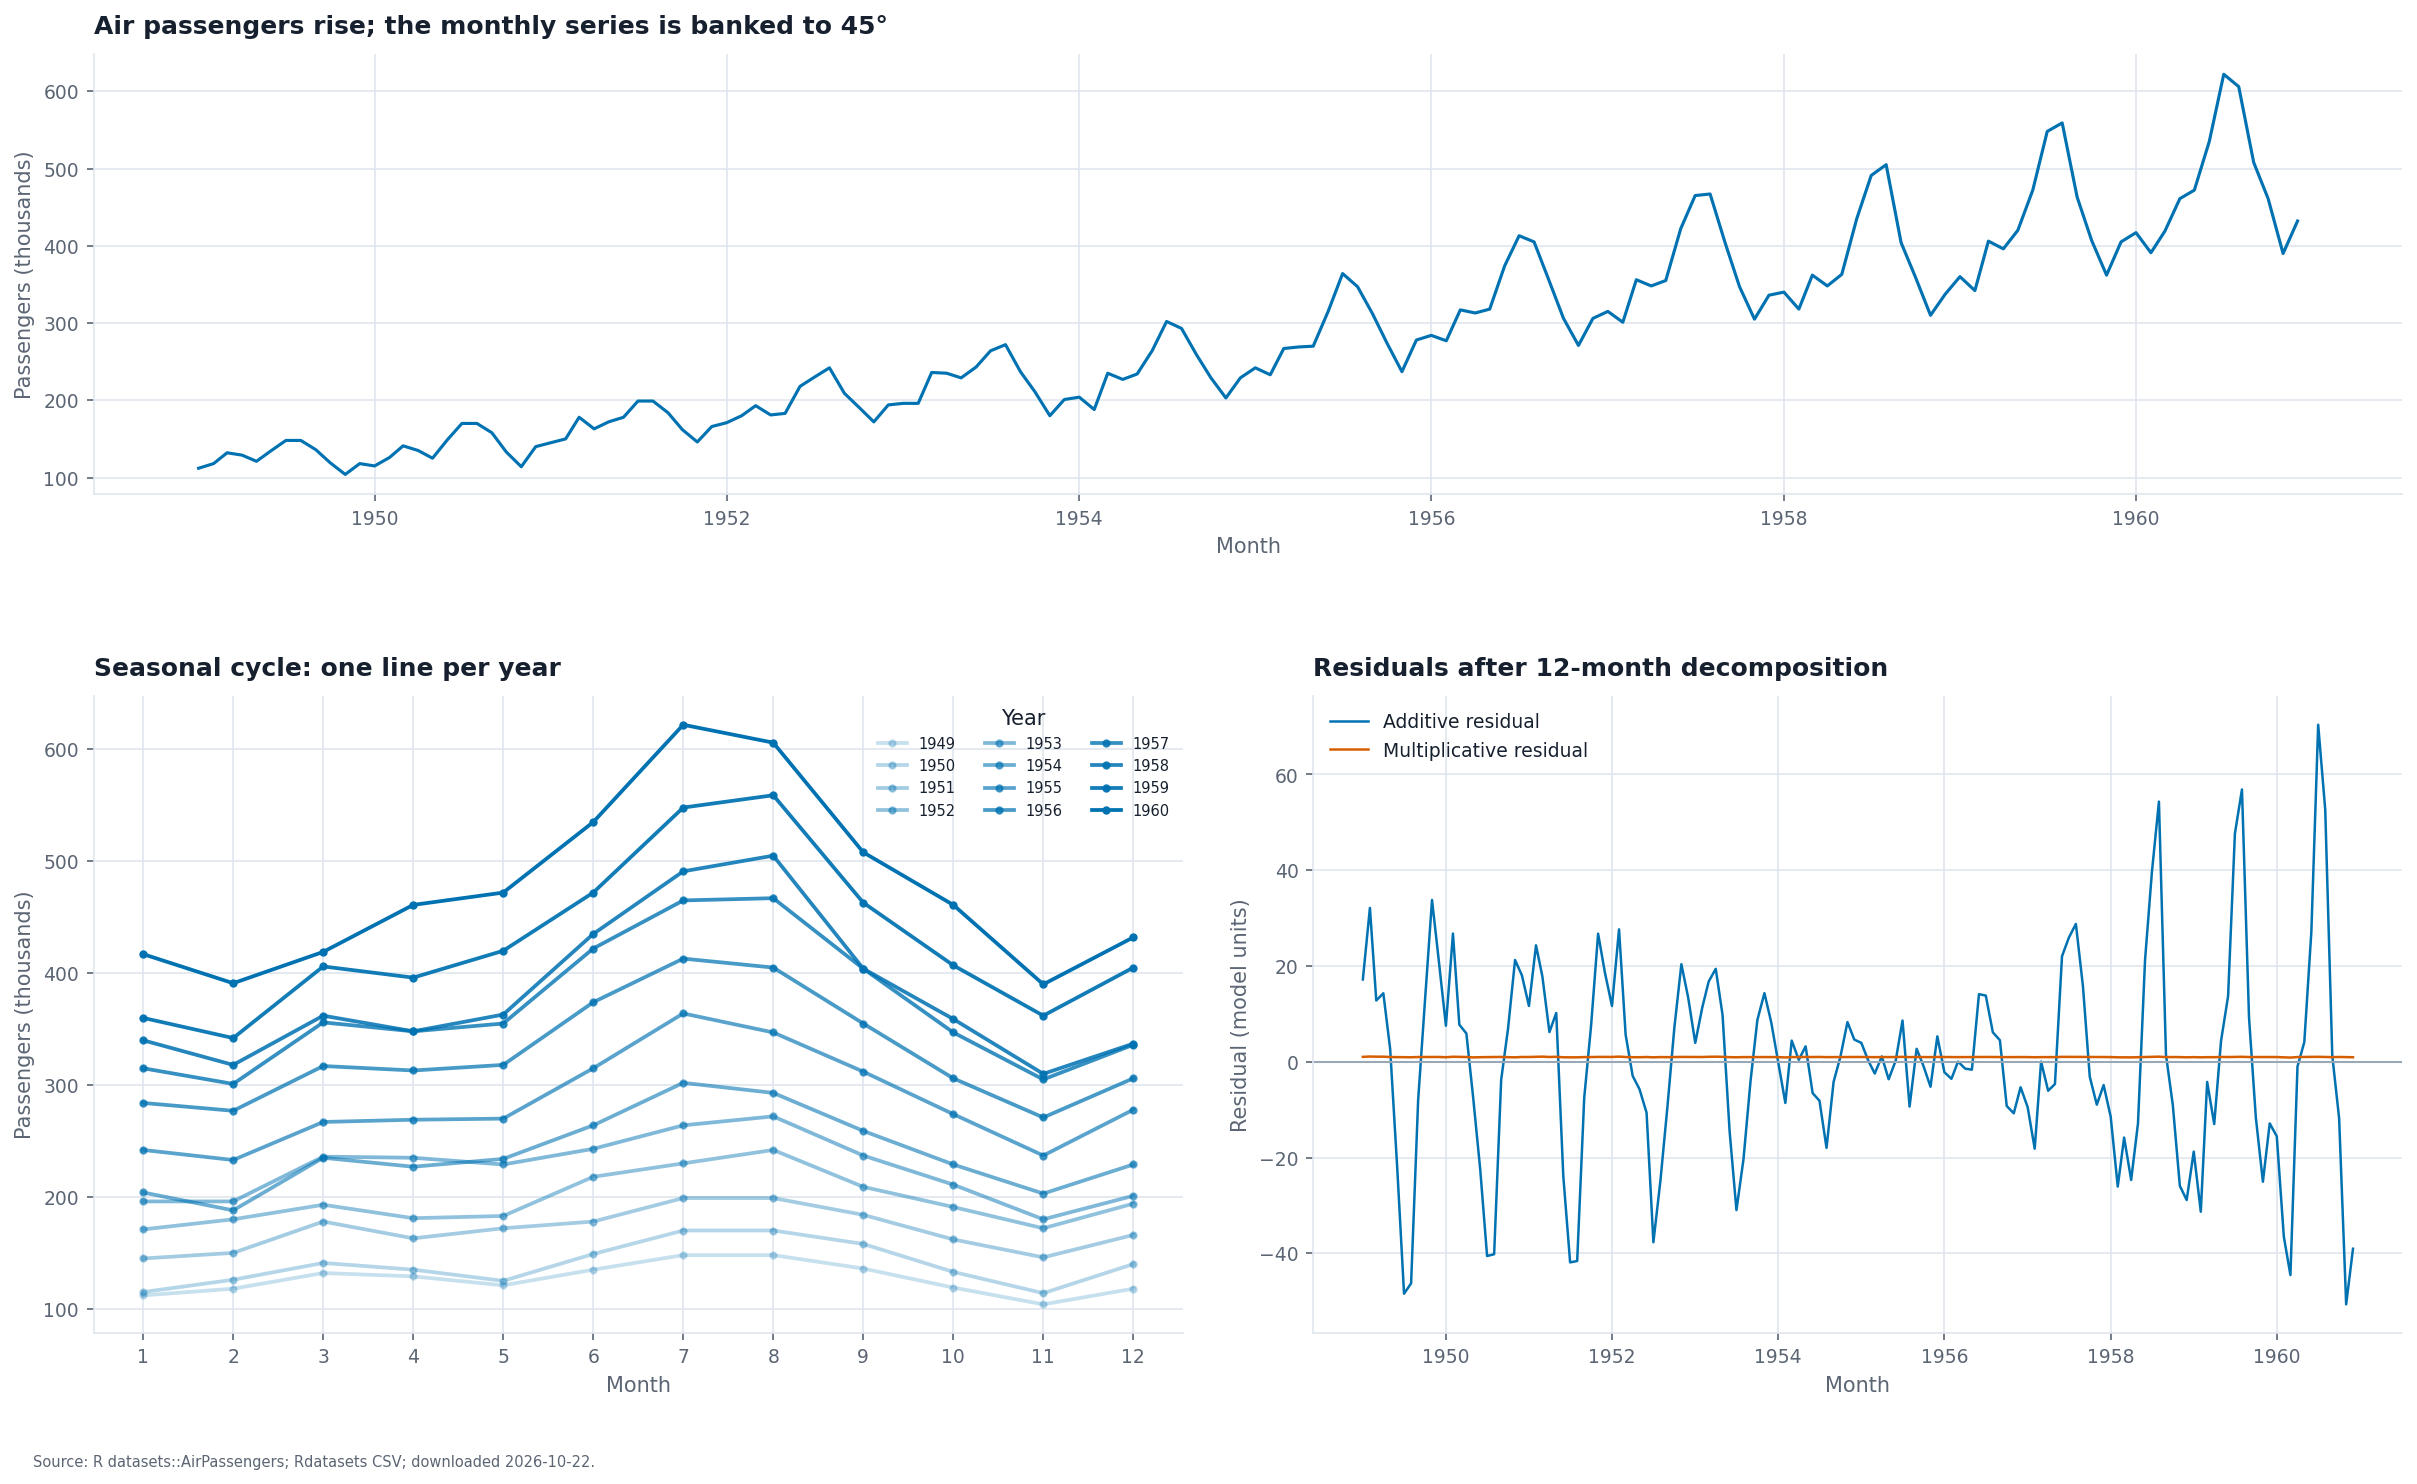

Exported: D:\7_Semester\data-visualization\week4\taskF_cycle.png | dpi=300


In [2]:
banked_size = banked_figsize(s.to_numpy(), width=8.5)
print(f"Banked figure size: {banked_size[0]:.2f} × {banked_size[1]:.2f} inches "
      "(height computed by tslib.banked_figsize for median absolute segment slope).")

add = seasonal_decompose(s, model="additive", period=12, extrapolate_trend="period")
mult = seasonal_decompose(s, model="multiplicative", period=12, extrapolate_trend="period")
fig = plt.figure(figsize=(16, 10), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1])
ax_series = fig.add_subplot(gs[0, :])
ax_cycle = fig.add_subplot(gs[1, 0])
ax_resid = fig.add_subplot(gs[1, 1])

ax_series.plot(s.index, s, color=PALETTE["series"][0], linewidth=1.5)
ax_series.set_box_aspect(banked_size[1] / banked_size[0])
ax_series.set_title("Air passengers rise; the monthly series is banked to 45°")
ax_series.set_xlabel("Month")
ax_series.set_ylabel("Passengers (thousands)")
ax_cycle.set_title("Seasonal cycle: one line per year")
cycle_plot(ax_cycle, s, by="month", color=PALETTE["series"][0])
ax_cycle.set_ylabel("Passengers (thousands)")
ax_cycle.legend(title="Year", ncol=3, fontsize=7)
ax_resid.plot(add.resid.index, add.resid, color=PALETTE["series"][0],
              label="Additive residual", linewidth=1.2)
ax_resid.plot(mult.resid.index, mult.resid, color=PALETTE["series"][1],
              label="Multiplicative residual", linewidth=1.2)
ax_resid.axhline(0, color=PALETTE["muted"], linewidth=1)
ax_resid.set(title="Residuals after 12-month decomposition",
             xlabel="Month", ylabel="Residual (model units)")
ax_resid.legend()

figure_path = WEEK4_DIR / "taskF_cycle.png"
save_fig(fig, figure_path, note="Source: R datasets::AirPassengers; Rdatasets CSV; downloaded 2026-10-22.")
plt.show()
print("Exported:", figure_path, "| dpi=300")

## Answer in two sentences, with evidence

In [3]:
add_amp = float(add.seasonal.max() - add.seasonal.min())
mult_amp = float(mult.seasonal.max() - mult.seasonal.min())
mult_swing_pct = (mult_amp / float(mult.seasonal.mean())) * 100
first_trend = float(add.trend.iloc[:12].mean())
last_trend = float(add.trend.iloc[-12:].mean())
print(f"Additive seasonal peak-to-trough amplitude: {add_amp:.1f} thousand passengers.")
print(f"Multiplicative seasonal factor peak-to-trough: {mult_amp:.3f} "
      f"({mult_swing_pct:.1f}% of its mean).")
print(f"Mean additive trend: first year={first_trend:.1f}, final year={last_trend:.1f} thousand.")
print(
    f"The additive seasonal swing is {add_amp:.1f} thousand passengers peak-to-trough, "
    f"while the multiplicative seasonal factor swings {mult_swing_pct:.1f}% of its mean; "
    "the growing absolute swing is therefore predominantly proportional to the rising passenger base, "
    "not evidence by itself that seasonality's relative strength is increasing. "
    f"The trend rises from about {first_trend:.1f} to {last_trend:.1f} thousand passengers "
    "per typical month, which is why the additive residual grows in absolute units."
)

Additive seasonal peak-to-trough amplitude: 128.4 thousand passengers.
Multiplicative seasonal factor peak-to-trough: 0.432 (43.2% of its mean).
Mean additive trend: first year=124.8, final year=479.8 thousand.
The additive seasonal swing is 128.4 thousand passengers peak-to-trough, while the multiplicative seasonal factor swings 43.2% of its mean; the growing absolute swing is therefore predominantly proportional to the rising passenger base, not evidence by itself that seasonality's relative strength is increasing. The trend rises from about 124.8 to 479.8 thousand passengers per typical month, which is why the additive residual grows in absolute units.


**Limitations.** This is a single historical series, not a causal analysis.
Additive and multiplicative residuals are in different units (passengers
versus ratios); compare their structure, not their raw magnitudes. The
source's category is the calendar month-of-year, derived from the monthly
date.